In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import io
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import random

# --- Training Loop with Metric Tracking---

epoch_count = 60
best_val_accuracy = 0.0
patience = 12
patience_counter = 0
model_save_path = 'best_vgg_model_normalized.pth'


In [2]:
# --- CNN Architecture ---
class VggCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(VggCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(9, 64, kernel_size=3, padding=1), # 9 input channels
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [17]:
# In[2]:
# --- Helper function to pre-fetch record metadata ---
def get_initial_records_and_map(db_url_str):
    """
    Connects to the database, fetches all relevant record IDs and surface groups,
    builds a label map, and splits data into training and validation record lists.
    Returns:
        train_records_list (list of (id, label_idx) tuples)
        val_records_list (list of (id, label_idx) tuples)
        label_map (dict mapping surface_group_name to label_idx)
    """
    engine = create_engine(db_url_str)
    all_records_from_db = []
    label_map = {}
    train_records_list = []
    val_records_list = []

    try:
        with engine.connect() as conn:
            result = conn.execute(text("""
                SELECT id, surface_group FROM final_balanced_trail_segments
                WHERE image_data IS NOT NULL AND surface_group IS NOT NULL
            """))
            all_records_from_db = result.fetchall()

        if not all_records_from_db:
            print("Warning: No records found in database during initial data fetch. Datasets will be empty.")
            return train_records_list, val_records_list, label_map

        # Build label_map
        unique_labels = sorted(list(set(r[1] for r in all_records_from_db)))
        label_map = {label: idx for idx, label in enumerate(unique_labels)}

        # Convert to (id, label_idx)
        all_records_with_labels = [(r[0], label_map[r[1]]) for r in all_records_from_db]

        # Split
        train_records_list, val_records_list = train_test_split(
            all_records_with_labels, test_size=0.2, random_state=42,
            stratify=[r[1] for r in all_records_with_labels] if len(all_records_with_labels) > 1 else None # Stratify if possible
        )
        print(f"Pre-fetched data: {len(train_records_list)} train, {len(val_records_list)} val records. Label map size: {len(label_map)}")

    except Exception as e:
        print(f"Error during initial data fetch: {e}")
    finally:
        if engine:
            engine.dispose() # Close all connections pooled by the engine

    return train_records_list, val_records_list, label_map


# --- Dataset Class (modified to accept pre-fetched records) ---
class TrailSegmentDataset(Dataset):
    def __init__(self, db_url, records_list, label_map, transform=None, for_stats_calc=False):
        self.db_url = db_url
        self.engine = None # Will be initialized lazily in each worker
        self.records = records_list # List of (id, label_idx)
        self.label_map = label_map
        self.transform = transform
        self.for_stats_calc = for_stats_calc # Flag for stats calculation mode

    def _get_engine(self):
        if self.engine is None:
            self.engine = create_engine(self.db_url, pool_size=5, max_overflow=5) # Adjust pool_size if needed for workers
        return self.engine

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        current_engine = self._get_engine()
        seg_id, label = self.records[idx]

        try:
            with current_engine.connect() as conn:
                result = conn.execute(text("SELECT image_data FROM final_balanced_trail_segments WHERE id = :id"), {"id": seg_id})
                image_bytes = result.scalar()

            if image_bytes is None:
                print(f"Warning: Image data is None for segment ID: {seg_id} (label: {label}).")
                # For stats calculation, we might want to skip. For training, this could be an error or needs a placeholder.
                if self.for_stats_calc:
                    return None, label # Signal to skip this item for stats
                else: # During actual training/validation
                    raise ValueError(f"Image data is None for segment ID: {seg_id}")

            image_array = np.load(io.BytesIO(image_bytes))
            image_array = image_array.astype(np.float32)

            if self.transform:
                image = self.transform(image_array)
            else: # Should only happen if for_stats_calc is True and transform is None
                image = image_array
            return image, label

        except Exception as e:
            print(f"Error in __getitem__ for seg_id {seg_id}: {e}")
            if self.for_stats_calc:
                return None, label # Signal to skip
            else:
                # Re-raise or return a dummy tensor to prevent crashing the whole training.
                # This depends on how you want to handle corrupted data.
                # For now, re-raising to make it visible.
                raise

In [4]:
# In[3]:
# --- Database URL ---
db_url = os.getenv('DATABASE_URL', "postgresql://markfinlay:@localhost:5432/osm")

# --- Pre-fetch initial record lists and label_map ---
# This is done ONCE in the main process
train_img_records, val_img_records, global_label_map = get_initial_records_and_map(db_url)

# --- Calculate Mean and Std for Normalization (only on training data) ---
print("Calculating mean and std for normalization on the training set...")
# Create a temporary dataset instance for the training split *without normalization in transform*
# to iterate over raw numpy arrays.
# Pass only the training records to this temporary dataset.
temp_train_dataset_for_stats = TrailSegmentDataset(db_url, train_img_records, global_label_map, transform=None, for_stats_calc=True)

all_train_images_list = []

print(f"Loading {len(temp_train_dataset_for_stats)} training images to calculate normalization stats...")
valid_images_count = 0
for i in range(len(temp_train_dataset_for_stats)):
    image_np, _ = temp_train_dataset_for_stats[i]
    if image_np is not None: # Check if image was loaded successfully (not None from __getitem__)
        all_train_images_list.append(image_np)
        valid_images_count +=1


all_train_images_np = np.stack(all_train_images_list, axis=0)
print(f"Shape of stacked training images for stats: {all_train_images_np.shape}")
channel_means = np.mean(all_train_images_np, axis=(0, 1, 2))
channel_stds = np.std(all_train_images_np, axis=(0, 1, 2))
epsilon = 1e-6
channel_stds = np.maximum(channel_stds, epsilon)

print(f"Calculated Channel Means: {channel_means.tolist()}")
print(f"Calculated Channel Stds: {channel_stds.tolist()}")


# --- Define Final Transforms with Normalization ---
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
])

# --- Create Final Datasets and DataLoaders ---
# Initialize datasets with pre-fetched records and the global label map
train_dataset = TrailSegmentDataset(db_url, train_img_records, global_label_map, transform=train_transform)
val_dataset = TrailSegmentDataset(db_url, val_img_records, global_label_map, transform=val_transform)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}") # val_dataset might be empty if train_test_split results in it

# For MPS, num_workers > 0 can be unstable. Start with 0.
# If using CUDA on another system, you can increase num_workers.
num_loader_workers = 0
use_pin_memory = False
if torch.cuda.is_available(): # Only use pin_memory with CUDA and workers
    use_pin_memory = True 
    # num_loader_workers = 4 # Example for CUDA
elif torch.backends.mps.is_available():
    print("MPS device detected. Setting num_workers to 0 and pin_memory to False for DataLoader for stability.")
    # num_workers > 0 with MPS is often problematic.

print(f"Using num_workers = {num_loader_workers} and pin_memory = {use_pin_memory} for DataLoaders.")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=num_loader_workers, pin_memory=use_pin_memory)
# Ensure val_loader can handle val_dataset being empty if all data went to train
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=num_loader_workers, pin_memory=use_pin_memory) if len(val_dataset) > 0 else None

print("Global Label mapping:", global_label_map if global_label_map else "N/A")

Pre-fetched data: 98096 train, 24524 val records. Label map size: 5
Calculating mean and std for normalization on the training set...
Loading 98096 training images to calculate normalization stats...
Shape of stacked training images for stats: (98096, 32, 32, 9)
Calculated Channel Means: [0.2704830765724182, 0.2651905417442322, 0.24170875549316406, 0.04852844402194023, 0.08895786851644516, 0.10506097972393036, 0.0670185536146164, 0.043866924941539764, 0.1670200675725937]
Calculated Channel Stds: [0.657516598701477, 0.6269733309745789, 0.6625603437423706, 0.08884993195533752, 0.1327875852584839, 0.16703945398330688, 0.09218523651361465, 0.061533838510513306, 0.40868088603019714]
Training dataset size: 98096
Validation dataset size: 24524
MPS device detected. Setting num_workers to 0 and pin_memory to False for DataLoader for stability.
Using num_workers = 0 and pin_memory = False for DataLoaders.
Global Label mapping: {'asphalt': 0, 'grass': 1, 'gravel': 2, 'mud/dirt': 3, 'paved': 4}


In [5]:
# In[4]:
# --- Class Distribution and Weights ---
from collections import Counter

# train_labels are the indices already stored in train_img_records
train_label_indices = [label_idx for _, label_idx in train_img_records]
print("Training set class distribution (indices):", Counter(train_label_indices))

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

counts = Counter(train_label_indices)
total_samples = sum(counts.values())
num_classes = len(global_label_map)

weights = []

for i in range(num_classes):
    class_count = counts.get(i, 0)
    if class_count == 0:
        print(f"Warning: Class index {i} has 0 instances in the training set. Assigning weight 1.0.")
        weights.append(1.0)
    else:
        weights.append(total_samples / (num_classes * class_count))
class_weights = torch.tensor(weights, dtype=torch.float).to(device)

print("Calculated class weights:")
idx_to_label_name = {idx: name for name, idx in global_label_map.items()}
for i, w_val in enumerate(weights):
    class_name = idx_to_label_name.get(i, f"Unknown_Class_{i}")
    print(f"Class {i} ('{class_name}'): weight = {w_val:.4f}, count = {counts.get(i, 0)}")


Training set class distribution (indices): Counter({1: 19620, 4: 19619, 0: 19619, 2: 19619, 3: 19619})
Using device: mps
Calculated class weights:
Class 0 ('asphalt'): weight = 1.0000, count = 19619
Class 1 ('grass'): weight = 1.0000, count = 19620
Class 2 ('gravel'): weight = 1.0000, count = 19619
Class 3 ('mud/dirt'): weight = 1.0000, count = 19619
Class 4 ('paved'): weight = 1.0000, count = 19619


In [6]:
# In[5]:
# --- Model, Optimizer, Criterion ---
model = VggCNN(num_classes=len(global_label_map)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
# Pass class_weights only if it's not None and has elements
criterion = nn.CrossEntropyLoss(weight=class_weights if class_weights is not None and len(class_weights) > 0 else None)


In [7]:
# In[6]:
# Initialize lists to store metrics for plotting
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
    'batch_loss': []
}

print(f"Starting training for {epoch_count} epochs on device: {device}")

for epoch in range(epoch_count):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for i, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        history['batch_loss'].append(loss.item()) # Store batch loss
        
        preds_train = outputs.argmax(dim=1)
        train_correct += (preds_train == labels).sum().item()
        train_total += labels.size(0)
        
        if (i + 1) % 100 == 0:
            print(f"  Epoch [{epoch+1}/{epoch_count}], Batch [{i+1}/{len(train_loader)}], Batch Loss: {loss.item():.4f}")

    # Calculate and store epoch metrics for training
    epoch_loss = running_loss / train_total if train_total > 0 else 0
    epoch_train_accuracy = 100 * train_correct / train_total if train_total > 0 else 0
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_train_accuracy)
    
    print(f"Epoch [{epoch+1}/{epoch_count}] - Training Loss: {epoch_loss:.4f}, Training Accuracy: {epoch_train_accuracy:.2f}%")

    # Validation
    if val_loader and len(val_loader) > 0:
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss_val = criterion(outputs, labels)
                val_loss += loss_val.item() * images.size(0)
                preds_val = outputs.argmax(dim=1)
                val_correct += (preds_val == labels).sum().item()
                val_total += labels.size(0)

        # Calculate and store epoch metrics for validation
        epoch_val_loss = val_loss / val_total if val_total > 0 else 0
        epoch_val_accuracy = 100 * val_correct / val_total if val_total > 0 else 0
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_accuracy)
        
        print(f"→ Epoch [{epoch+1}/{epoch_count}] - Validation Loss: {epoch_val_loss:.4f}, Validation Accuracy: {epoch_val_accuracy:.2f}%")

        if epoch_val_accuracy > best_val_accuracy:
            best_val_accuracy = epoch_val_accuracy
            patience_counter = 0
            torch.save(model.state_dict(), model_save_path)
            print(f"Saved new best model to {model_save_path} with accuracy: {best_val_accuracy:.2f}%")
        else:
            patience_counter += 1
            
        if patience_counter >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation accuracy.")
            break
    else:
         print(f"→ Epoch [{epoch+1}/{epoch_count}] - Validation skipped.")

print("Training complete.")


Starting training for 60 epochs on device: mps
  Epoch [1/60], Batch [100/3066], Batch Loss: 1.5341
  Epoch [1/60], Batch [200/3066], Batch Loss: 1.5824
  Epoch [1/60], Batch [300/3066], Batch Loss: 1.4622
  Epoch [1/60], Batch [400/3066], Batch Loss: 1.1987
  Epoch [1/60], Batch [500/3066], Batch Loss: 1.3968
  Epoch [1/60], Batch [600/3066], Batch Loss: 1.4360
  Epoch [1/60], Batch [700/3066], Batch Loss: 1.4683
  Epoch [1/60], Batch [800/3066], Batch Loss: 1.4792
  Epoch [1/60], Batch [900/3066], Batch Loss: 1.2348
  Epoch [1/60], Batch [1000/3066], Batch Loss: 1.4095
  Epoch [1/60], Batch [1100/3066], Batch Loss: 1.5698
  Epoch [1/60], Batch [1200/3066], Batch Loss: 1.4945
  Epoch [1/60], Batch [1300/3066], Batch Loss: 1.4451
  Epoch [1/60], Batch [1400/3066], Batch Loss: 1.3098
  Epoch [1/60], Batch [1500/3066], Batch Loss: 1.4286
  Epoch [1/60], Batch [1600/3066], Batch Loss: 1.3741
  Epoch [1/60], Batch [1700/3066], Batch Loss: 1.3179
  Epoch [1/60], Batch [1800/3066], Batch Los

In [10]:
import json
# --- Save the history dictionary to a JSON file ---
history_save_path = 'vgg_training_history.json'
with open(history_save_path, 'w') as f:
    json.dump(history, f, indent=4)
print(f"Training history saved to {history_save_path}")

Training history saved to vgg_training_history.json


In [11]:
print(f"\n--- Loading saved model from {model_save_path} for inference/evaluation ---")

# 1. Re-create the model architecture
#    It must be the EXACT same architecture as the one you saved.
#    The number of classes must match.
loaded_model = VggCNN(num_classes=len(global_label_map))

# 2. Load the saved state dictionary
#    map_location is important if you saved the model on a GPU and want to load it on a CPU, or vice versa.
loaded_model.load_state_dict(torch.load(model_save_path, map_location=device))

# 3. Move the model to the correct device (e.g., 'mps', 'cuda', or 'cpu')
loaded_model.to(device)

# 4. Set the model to evaluation mode
#    This is crucial! It disables layers like Dropout and normalizes batch statistics correctly for inference.
loaded_model.eval()

print("Model loaded successfully and set to evaluation mode.")


--- Loading saved model from best_vgg_model_normalized.pth for inference/evaluation ---
Model loaded successfully and set to evaluation mode.


In [12]:
# --- 1. Get All Predictions from the Validation Set ---
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = loaded_model(images)
        preds = torch.argmax(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [13]:
# --- 2. Generate Classification Report ---
# This provides precision, recall, and F1-score for each class.
# It's perfect for a detailed results table in your thesis.

# Get class names from the label map
class_names = [name for name, idx in sorted(global_label_map.items(), key=lambda item: item[1])]

print("--- Classification Report ---")
report = classification_report(all_labels, all_preds, target_names=class_names)
print(report)


--- Classification Report ---
              precision    recall  f1-score   support

     asphalt       0.44      0.62      0.51      4905
       grass       0.40      0.61      0.48      4904
      gravel       0.50      0.44      0.46      4905
    mud/dirt       0.39      0.27      0.32      4905
       paved       0.63      0.31      0.41      4905

    accuracy                           0.45     24524
   macro avg       0.47      0.45      0.44     24524
weighted avg       0.47      0.45      0.44     24524



Confusion matrix plot saved to 'vgg_scratch_confusion_matrix.png'


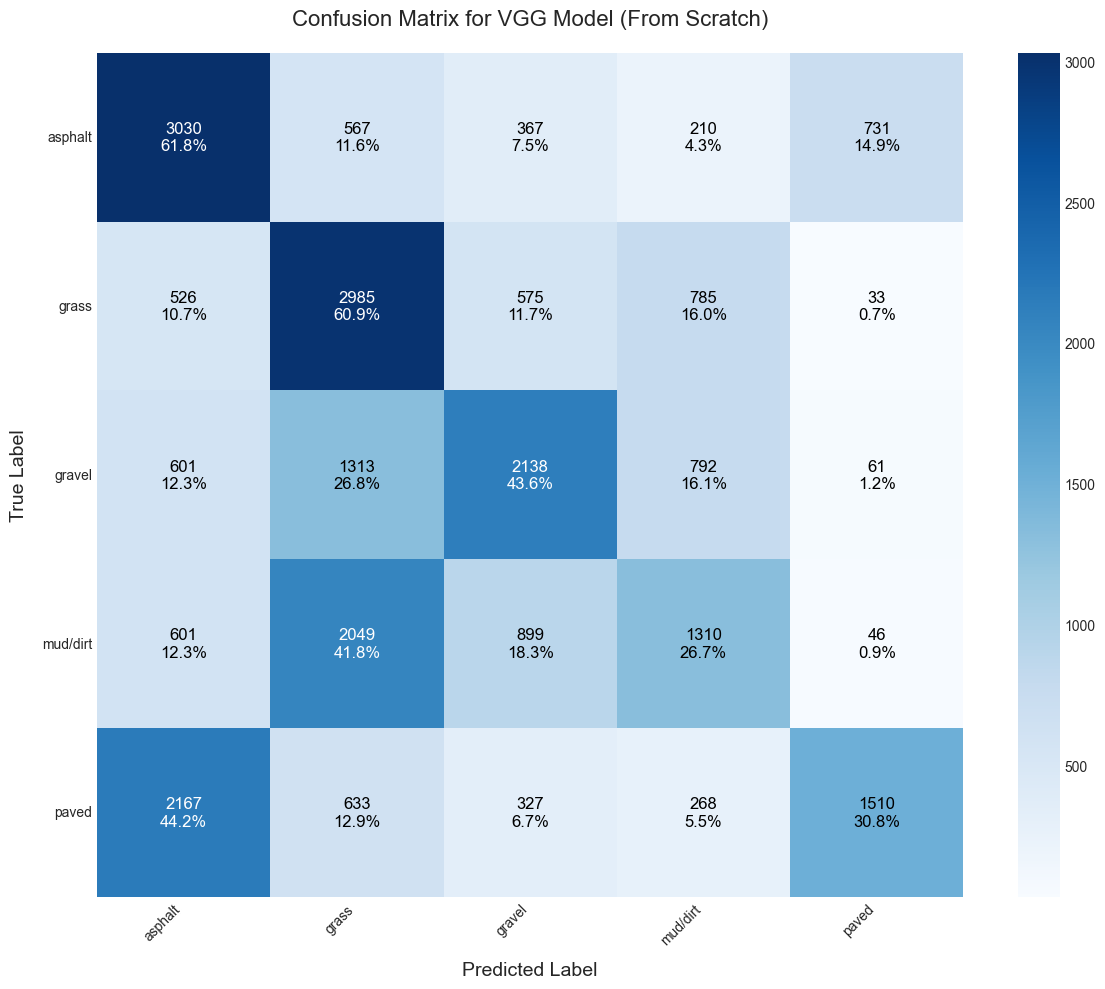

In [16]:
# --- 3. Generate and Plot Confusion Matrix ---
# This is essential for visualizing which classes are most often confused.

cm = confusion_matrix(all_labels, all_preds)
class_names = [name for name, idx in sorted(global_label_map.items(), key=lambda item: item[1])]

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 10))

# Create the heatmap
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=ax, xticklabels=class_names, yticklabels=class_names)

# Add custom annotations with counts and percentages
for i in range(len(class_names)):
    for j in range(len(class_names)):
        count = cm[i, j]
        row_sum = np.sum(cm[i])
        percentage = f"{(count / row_sum) * 100:0.1f}%" if row_sum > 0 else "0.0%"
        # FIX: Renamed variable from 'text' to 'annotation_text' to avoid conflict
        annotation_text = f"{count}\\n{percentage}"
        text_color = "white" if cm[i, j] > (cm.max() / 2) else "black"
        ax.text(j + 0.5, i + 0.5, annotation_text, ha='center', va='center', color=text_color, fontsize=12)

# Set titles and labels
ax.set_xlabel('Predicted Label', fontsize=14, labelpad=10)
ax.set_ylabel('True Label', fontsize=14, labelpad=10)
ax.set_title('Confusion Matrix for VGG Model (From Scratch)', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# --- ADDED THIS SECTION TO SAVE THE FILE ---
output_filename = "vgg_scratch_confusion_matrix.png"
plt.savefig(output_filename, dpi=300)
print(f"Confusion matrix plot saved to '{output_filename}'")
# ---

plt.show()

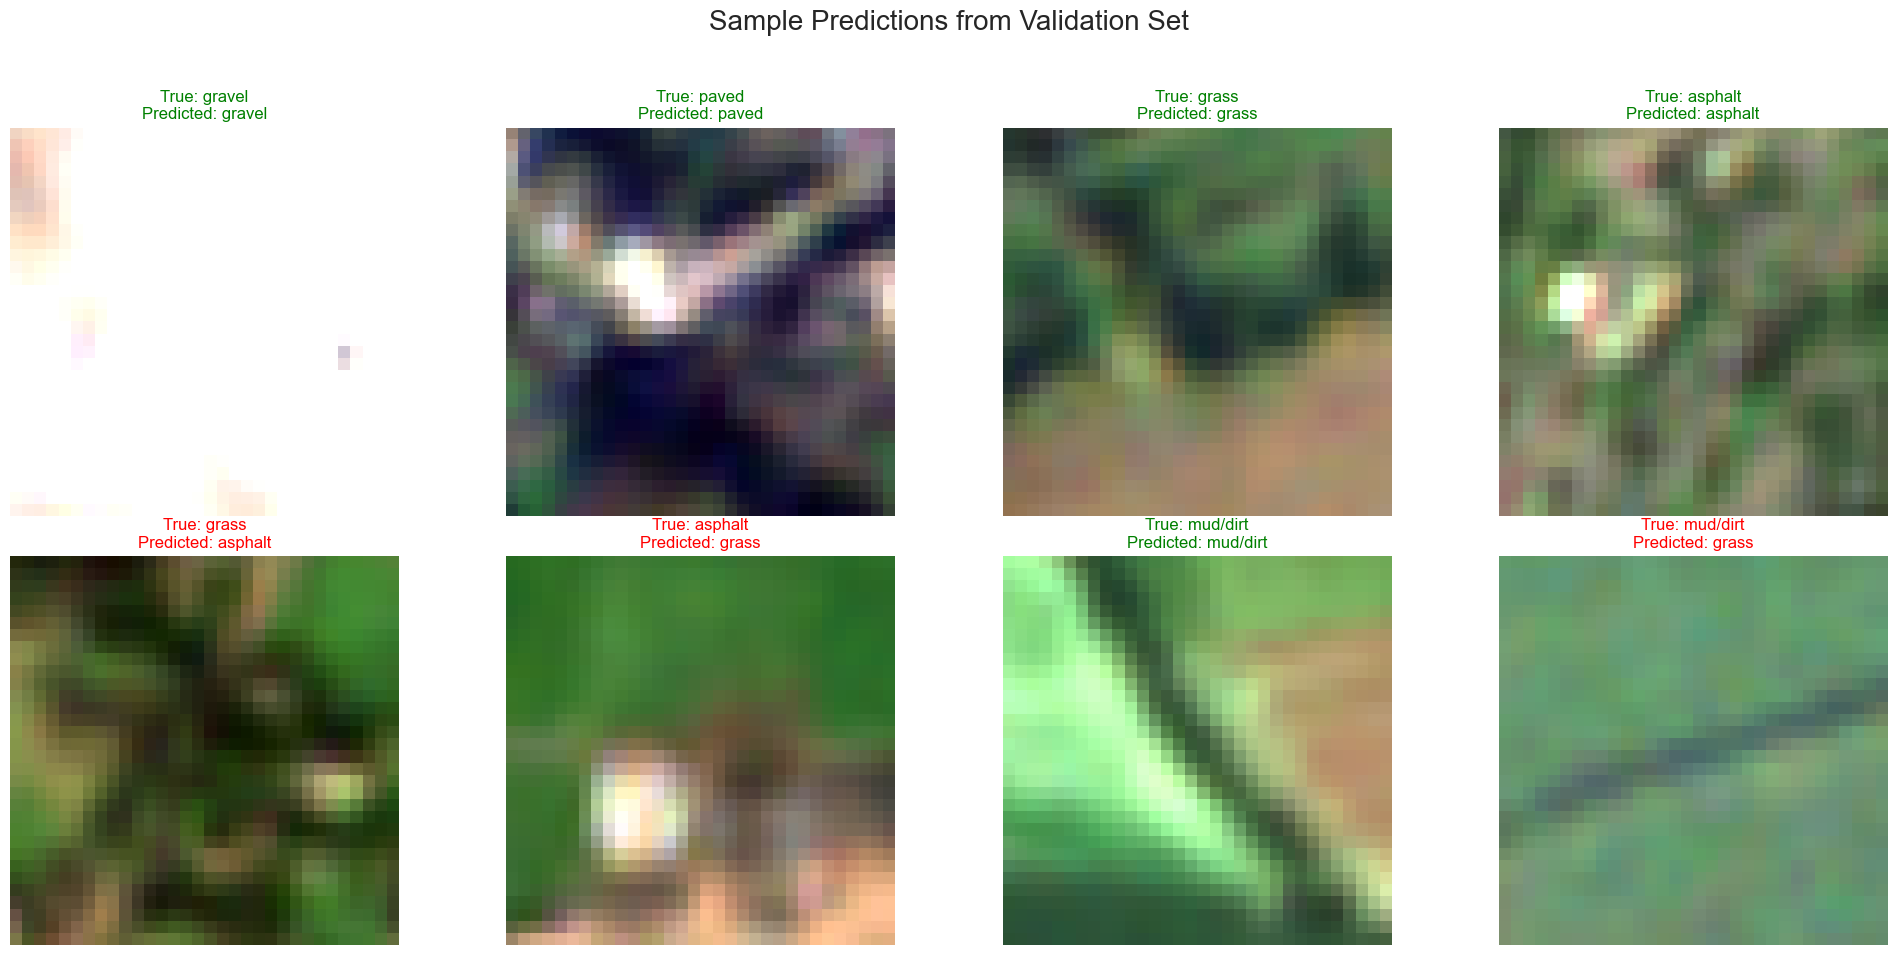

In [19]:
from sqlalchemy import text
# --- 4. Visualize Sample Predictions ---
# This qualitative analysis helps you discuss *why* the model makes certain errors.
# You can see if certain images are inherently ambiguous.

def denormalize(tensor, means, stds):
    """Denormalizes a tensor image with mean and standard deviation."""
    # Clone to avoid modifying the original tensor
    denorm_tensor = tensor.clone()
    for t, m, s in zip(denorm_tensor, means, stds):
        t.mul_(s).add_(m)
    return denorm_tensor

# We need the means and stds calculated earlier for denormalization
# Replace these with your actual calculated values if they are not in scope
# For visualization, we only need the first 3 channels (R, G, B)
vis_means = channel_means[:3]
vis_stds = channel_stds[:3]

# Get a random batch from the validation loader
images, labels = next(iter(val_loader))
images_to_device = images.to(device)

# Get model predictions for this batch
outputs = loaded_model(images_to_device)
preds = torch.argmax(outputs, 1)

# Inverse mapping from index to class name
idx_to_label = {idx: name for name, idx in global_label_map.items()}

# Plot 8 random images from the batch
plt.figure(figsize=(20, 10))
plt.suptitle('Sample Predictions from Validation Set', fontsize=20)

for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    
    # Select the first 3 channels (RGB) for visualization
    img_rgb = images[i][:3, :, :]
    
    # Denormalize the image for correct color display
    img_denorm = denormalize(img_rgb, vis_means, vis_stds)
    
    # Transpose from (C, H, W) to (H, W, C) for plotting
    img_display = np.transpose(img_denorm.cpu().numpy(), (1, 2, 0))
    
    # Clip values to [0, 1] to prevent matplotlib warnings
    img_display = np.clip(img_display, 0, 1)

    plt.imshow(img_display)
    
    true_label = idx_to_label[labels[i].item()]
    pred_label = idx_to_label[preds[i].item()]
    
    # Set title color to green for correct predictions, red for incorrect
    title_color = 'green' if true_label == pred_label else 'red'
    
    plt.title(f"True: {true_label}\nPredicted: {pred_label}", color=title_color, fontsize=12)
    plt.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()